In [36]:
%matplotlib inline

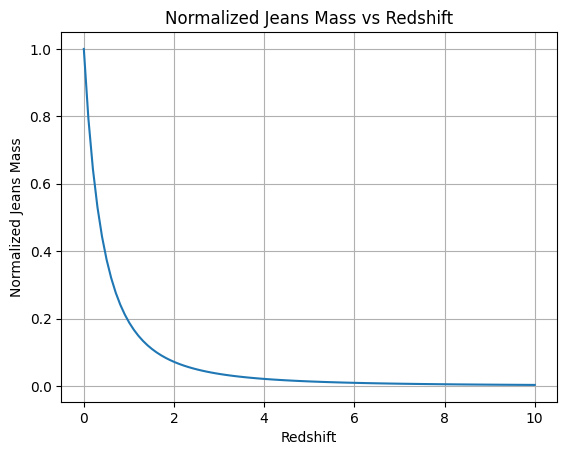

In [37]:
#Question 3(b)
import numpy as np
import matplotlib.pyplot as plt
w=-0.9
beta=1.5
gamma=(3/2)*(1+w+beta)
z=np.linspace(10,0,100)
a=1.0/(1+z)
M_J=a**gamma
plt.figure()
plt.plot(z,M_J)
plt.xlabel("Redshift")
plt.ylabel("Normalized Jeans Mass")
plt.title("Normalized Jeans Mass vs Redshift")
plt.grid()
plt.savefig("jeansmass.png")
plt.show()

(12497500,)


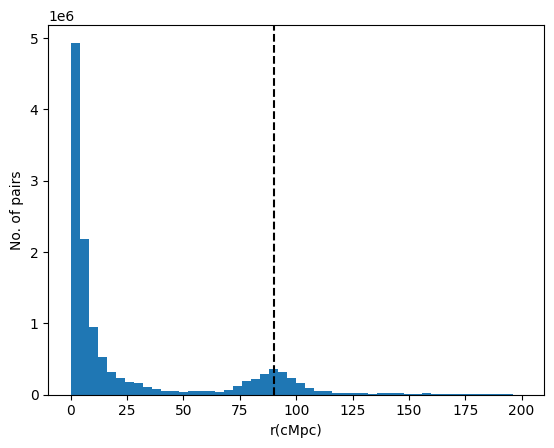

The BAO peak is at: 90.0 cMpc


In [70]:
#Question 4
import numpy as np
import matplotlib.pyplot as plt
dataset=np.loadtxt("BAO Galaxy Sample 2.txt")
N_rows = dataset.shape[0]
N_cols = dataset.shape[1]
distances=[]
for galaxy_indx in range(N_rows):
 x = dataset[galaxy_indx,0]
 y = dataset[galaxy_indx,1]
 z = dataset[galaxy_indx,2]
 for galaxy2_indx in range(galaxy_indx+1,N_rows):
      x2 = dataset[galaxy2_indx,0]
      y2 = dataset[galaxy2_indx,1]
      z2 = dataset[galaxy2_indx,2]
      distance=np.sqrt((x2-x)**2+(y2-y)**2+(z2-z)**2)
      distances.append(distance)
distances=np.array(distances)
print(np.shape(distances))
histogram,binn=np.histogram(distances,bins=50,range=(0,200))
bincenters=(binn[:-1]+binn[1:])/2
bao=bincenters>50
peak_index=np.argmax(histogram[bao])
bao_peak=bincenters[bao][peak_index]
plt.figure()
plt.hist(distances,bins=50,range=(0,200))
plt.axvline(bao_peak, color='black', linestyle='dashed')
plt.xlabel("r(cMpc)")
plt.ylabel("No. of pairs")
plt.savefig("BAOsample2.png")
plt.show()
print("The BAO peak is at:",bao_peak, "cMpc")

#Just changed the Sample 1 in loadtxt to Sample 2 to get the results for the other sample

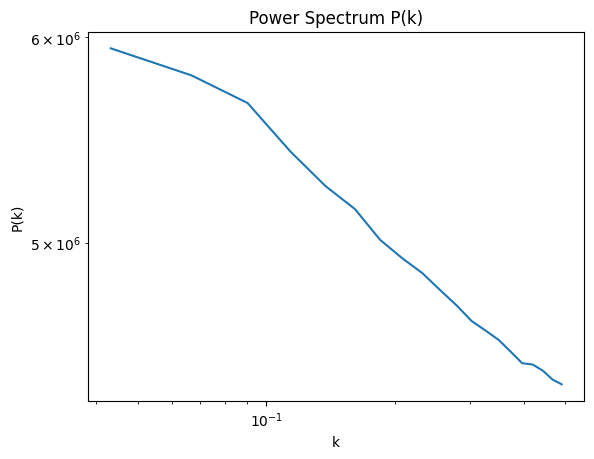

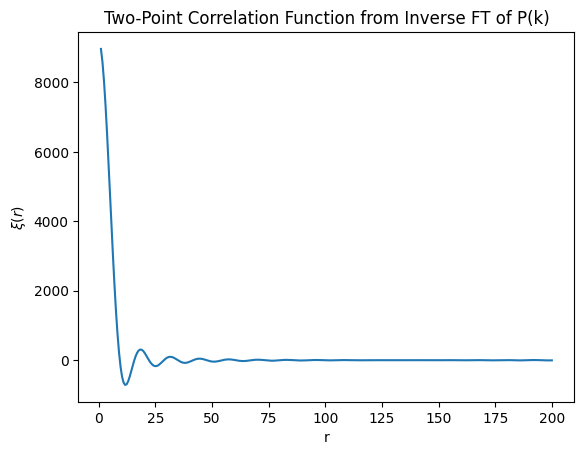

In [69]:
#Question 5
import numpy as np
import matplotlib.pyplot as plt
dataset=np.loadtxt("BAO Galaxy Sample 2.txt")
N_rows=dataset.shape[0]
x_gal=dataset[:,0]
y_gal=dataset[:,1]
z_gal=dataset[:,2]
N=32
L=200.0
cell_size=L/N
density=np.zeros((N,N,N))
for i in range(N_rows):
    fx=x_gal[i]/cell_size
    fy=y_gal[i]/cell_size
    fz=z_gal[i]/cell_size
    ix = int(fx)%N
    iy = int(fy)%N
    iz = int(fz)%N
    dx=fx-int(fx)
    dy=fy-int(fy)
    dz=fz-int(fz)
    density[ix%N,iy%N,iz%N]+=(1-dx)*(1-dy)*(1-dz)
    density[(ix+1)%N,iy%N,iz%N]+=dx*(1-dy)*(1-dz)
    density[ix%N,(iy+1)%N,iz%N]+=(1-dx)*dy*(1-dz)
    density[ix%N,iy%N,(iz+1)%N]+=(1-dx)*(1-dy)*dz
    density[(ix+1)%N,(iy+1)%N,iz%N]+=dx*dy*(1-dz)
    density[(ix+1)%N,iy%N,(iz+1)%N]+=dx*(1-dy)*dz
    density[ix%N,(iy+1)%N,(iz+1)%N]+=(1-dx)*dy*dz
    density[(ix+1)%N,(iy+1)%N,(iz+1)%N]+=dx*dy*dz
mean_density=np.mean(density)
delta=(density-mean_density)/mean_density
delta_k=np.fft.fftn(delta)*(L/N)**3 
V=L**3
power_3d=(np.abs(delta_k)**2)/V
n_bar=N_rows/V
power_3d-=1.0/n_bar
kx = np.fft.fftfreq(N,d=L/N)*2*np.pi
ky = np.fft.fftfreq(N,d=L/N)*2*np.pi
kz = np.fft.fftfreq(N,d=L/N)*2*np.pi
KX,KY,KZ=np.meshgrid(kx,ky,kz,indexing='ij')
K_mag=np.sqrt(KX**2+KY**2+KZ**2)
k_min=2*np.pi/L      
k_max=np.pi*N/L    
n_bins=20
k_bins=np.linspace(k_min,k_max,n_bins+1)
k_cen=(k_bins[:-1]+k_bins[1:])/2
P_k=np.zeros(n_bins)
for b in range(n_bins):
    shell=(K_mag>=k_bins[b])&(K_mag<k_bins[b+1])&(K_mag>0)
    P_k[b] = np.mean(power_3d[shell])
plt.figure()
plt.loglog(k_cen,P_k)
plt.xlabel("k")
plt.ylabel("P(k)")
plt.title("Power Spectrum P(k)")
plt.savefig("powerspectrum2.png")
plt.show()
r_arr=np.linspace(1,200,300)
xi_r=np.zeros(len(r_arr))
for j,r in enumerate(r_arr):
    sincterm=np.sinc(k_cen*r/np.pi)
    integrand=P_k*sincterm*k_cen**2
    xi_r[j]=(np.trapezoid(integrand,k_cen)/(2*np.pi**2))
plt.figure()
plt.plot(r_arr,xi_r)
plt.xlabel("r")
plt.ylabel(r"$\xi(r)$")
plt.title("Two-Point Correlation Function from Inverse FT of P(k)")
plt.savefig("ift of Pk2.png")
plt.show()

#again we changed the Sample 1 to Sample 2 in loadtxt for the other result